# 🏐 TracknetV1 — Análise Visual da Validação

Este notebook executa a validação do modelo TracknetV1 e oferece:
1. **Visualização por amostra** — Frame original + GT, heatmap predito, heatmap tratado
2. **Controle interativo** dos hiperparâmetros do postprocessing (sliders matplotlib)
3. **Métricas agregadas** (Precision, Recall, F1)
4. **Histograma de distâncias** GT → Predição

In [11]:
# ===== CONFIGURAÇÕES =====
# Ajuste os caminhos abaixo conforme sua máquina

MODEL_WEIGHTS_PATH = "assets/model.pt"   # Caminho do checkpoint do modelo

# Opção 1: Dataset unificado (split automático 80/20)
DATASET_PATH = "assets/val"  # contém frames_out/, gts/, labels/

# Opção 2: Caminhos separados para validação (se tiver split manual)
# Se preenchido, DATASET_PATH é ignorado
VAL_PATH = "assets/val"  # ex: "assets/val"  — contém frames_out/, gts/, labels/

# Parâmetros de execução
BATCH_SIZE = 1
MAX_VAL_SAMPLES = 20         # Quantas amostras processar (None = todas). Ideal p/ CPU.
MAX_SAMPLES_TO_SHOW = 20     # Quantas amostras guardar para visualização interativa
MIN_DIST_THRESHOLD = 50      # Distância máxima (px) para considerar TP
DEVICE = "cpu"               # "cuda" ou "cpu"

# Resolução do heatmap (saída do modelo)
HEATMAP_H = 360
HEATMAP_W = 640

In [12]:
import sys, os
import torch
import torch.nn as nn
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.widgets import Slider, Button
from scipy.spatial import distance

# Adiciona a raiz do projeto ao path
PROJECT_ROOT = os.path.abspath(".")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from models.TracknetV1 import BallTrackerNet
from datasets.TracknetV1Dataset import TracknetV1Dataset

print(f"PyTorch: {torch.__version__}")
print(f"CUDA disponível: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch: 2.4.1+cpu
CUDA disponível: False


## 1. Carregamento do Modelo e Dataset

In [13]:
# --- Modelo ---
model = BallTrackerNet()
device = DEVICE if torch.cuda.is_available() or DEVICE == 'cpu' else 'cpu'
model = model.to(device)

if os.path.exists(MODEL_WEIGHTS_PATH):
    model.load_state_dict(torch.load(MODEL_WEIGHTS_PATH, map_location=device))
    print(f"✅ Pesos carregados de: {MODEL_WEIGHTS_PATH}")
else:
    print(f"⚠️  Arquivo de pesos não encontrado: {MODEL_WEIGHTS_PATH}")
    print("   O modelo será usado com pesos aleatórios (resultados não significativos).")

model.eval()
print(f"Modelo em modo eval no device: {device}")

✅ Pesos carregados de: assets/model.pt
Modelo em modo eval no device: cpu


C:\Users\gears\AppData\Local\Temp\ipykernel_13588\482117565.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_WEIGHTS_PATH, map_loca

In [14]:
# --- Dataset de validação ---
if VAL_PATH is not None:
    val_dataset = TracknetV1Dataset(
        frames_path=os.path.join(VAL_PATH, "frames_out"),
        gts_path=os.path.join(VAL_PATH, "gts"),
        labels_path=os.path.join(VAL_PATH, "labels")
    )
    print(f"Dataset de validação carregado de: {VAL_PATH}")
else:
    full_dataset = TracknetV1Dataset(
        frames_path=os.path.join(DATASET_PATH, "frames_out"),
        gts_path=os.path.join(DATASET_PATH, "gts"),
        labels_path=os.path.join(DATASET_PATH, "labels")
    )
    train_size = int(0.8 * len(full_dataset))
    val_size = len(full_dataset) - train_size
    _, val_dataset = torch.utils.data.random_split(
        full_dataset, [train_size, val_size],
        generator=torch.Generator().manual_seed(42)
    )
    print(f"Dataset total: {len(full_dataset)} | Validação (20%): {val_size}")

# Limitar amostras para CPU
if MAX_VAL_SAMPLES is not None and MAX_VAL_SAMPLES < len(val_dataset):
    val_dataset = torch.utils.data.Subset(val_dataset, range(MAX_VAL_SAMPLES))
    print(f"⚡ Limitado a {MAX_VAL_SAMPLES} amostras para execução rápida em {device.upper()}")

val_loader = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)
print(f"Amostras: {len(val_dataset)} | Batches: {len(val_loader)}")

Dataset de validação carregado de: assets/val
⚡ Limitado a 20 amostras para execução rápida em CPU
Amostras: 20 | Batches: 20


## 2. Inferência — Coleta dos feature maps brutos

In [15]:
def get_original_frame(dataset, global_idx):
    """Recupera o frame original RGB a partir do dataset (funciona com Subsets aninhados)."""
    ds = dataset
    idx = global_idx
    while hasattr(ds, 'dataset'):
        if hasattr(ds, 'indices'):
            idx = ds.indices[idx]
        ds = ds.dataset
    path = ds.samples[idx][0]
    img = cv2.imread(path)
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img, path


# Detecta a resolução original a partir do primeiro frame
first_img, _ = get_original_frame(val_dataset, 0)
ORIG_H, ORIG_W = first_img.shape[:2]
SCALE_X = ORIG_W / HEATMAP_W  # ex: 1920/640 = 3.0
SCALE_Y = ORIG_H / HEATMAP_H  # ex: 1080/360 = 3.0
print(f"📐 Resolução original: {ORIG_W}x{ORIG_H}")
print(f"   Heatmap: {HEATMAP_W}x{HEATMAP_H}")
print(f"   Fator de escala: X={SCALE_X:.2f}, Y={SCALE_Y:.2f}")


# Coleta dados brutos da inferência
raw_results = []
criterion = nn.CrossEntropyLoss()
losses = []

print("\n🔄 Executando inferência...")
with torch.no_grad():
    sample_counter = 0
    for batch_idx, batch in enumerate(val_loader):
        inputs = batch[0].float().to(device)
        gt_tensor = torch.tensor(batch[1], dtype=torch.long, device=device)
        
        out = model(inputs)
        loss = criterion(out, gt_tensor)
        losses.append(loss.item())
        
        output = out.argmax(dim=1).detach().cpu().numpy()
        
        for i in range(len(output)):
            global_idx = batch_idx * BATCH_SIZE + i
            x_gt = batch[2][i].item() if torch.is_tensor(batch[2][i]) else batch[2][i]
            y_gt = batch[3][i].item() if torch.is_tensor(batch[3][i]) else batch[3][i]
            vis = batch[4][i].item() if torch.is_tensor(batch[4][i]) else batch[4][i]
            
            if len(raw_results) < MAX_SAMPLES_TO_SHOW:
                orig_img, frame_path = get_original_frame(val_dataset, global_idx)
                raw_results.append({
                    'frame': orig_img,
                    'frame_path': frame_path,
                    'feature_map': output[i].copy(),
                    'x_gt': x_gt,
                    'y_gt': y_gt,
                    'vis': vis,
                })
            sample_counter += 1
        
        if (batch_idx + 1) % 10 == 0 or batch_idx == len(val_loader) - 1:
            print(f"  Batch [{batch_idx+1}/{len(val_loader)}] | Loss: {np.mean(losses):.6f}")

print(f"\n✅ Inferência concluída! {sample_counter} amostras processadas.")
print(f"   {len(raw_results)} amostras guardadas para visualização interativa.")
print(f"   Loss média: {np.mean(losses):.6f}")

📐 Resolução original: 1920x1080
   Heatmap: 640x360
   Fator de escala: X=3.00, Y=3.00

🔄 Executando inferência...


C:\Users\gears\AppData\Local\Temp\ipykernel_13588\3462306117.py:36: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  gt_tensor = torch.tensor(batch[1], dtype=torch.long, device=device)


  Batch [10/20] | Loss: 0.032930
  Batch [20/20] | Loss: 0.027149

✅ Inferência concluída! 20 amostras processadas.
   20 amostras guardadas para visualização interativa.
   Loss média: 0.027149


## 3. 🎛️ Explorador Interativo de Postprocessing

Use os sliders para ajustar os hiperparâmetros do postprocessing em tempo real.

**Layout**: Esquerda = Frame original + GT | Centro = Heatmap predito (raw) | Direita = Heatmap tratado + detecção

> **Nota:** Se os sliders não responderem, troque `%matplotlib tk` por `%matplotlib qt`.

In [16]:
# Backend interativo para matplotlib
%matplotlib tk

In [17]:
def postprocess_with_params(feature_map, threshold=127, dp=1, min_dist=1,
                            param1=60, param2=10, min_radius=2, max_radius=7):
    """
    Postprocessing parametrizável do feature map.
    
    Coordenadas retornadas estão no espaço do HEATMAP (360x640).
    Para converter para resolução original, multiplique por SCALE_X / SCALE_Y.
    
    Retorna: x_hm, y_hm, heatmap_raw, heatmap_bin, circles
    """
    fm = feature_map.copy().astype(np.float64)
    fm *= 255
    fm = fm.reshape((HEATMAP_H, HEATMAP_W))
    fm = fm.astype(np.uint8)
    heatmap_raw = fm.copy()
    
    _, heatmap_bin = cv2.threshold(fm, int(threshold), 255, cv2.THRESH_BINARY)
    
    circles = None
    try:
        circles = cv2.HoughCircles(
            heatmap_bin, cv2.HOUGH_GRADIENT,
            dp=dp, minDist=max(1, int(min_dist)),
            param1=max(1, int(param1)), param2=max(1, int(param2)),
            minRadius=int(min_radius), maxRadius=int(max_radius)
        )
    except cv2.error:
        circles = None
    
    # Coordenadas no espaço do heatmap (360x640)
    x_hm, y_hm = None, None
    if circles is not None and len(circles) >= 1:
        x_hm = circles[0][0][0]  # no espaço do heatmap
        y_hm = circles[0][0][1]
    
    return x_hm, y_hm, heatmap_raw, heatmap_bin, circles


def hm_to_orig(x_hm, y_hm):
    """Converte coordenadas do heatmap (360x640) para resolução original."""
    return x_hm * SCALE_X, y_hm * SCALE_Y


def orig_to_hm(x_orig, y_orig):
    """Converte coordenadas da resolução original para heatmap (360x640)."""
    return x_orig / SCALE_X, y_orig / SCALE_Y


print(f"✅ Funções prontas. Escala: {SCALE_X:.1f}x{SCALE_Y:.1f}")

✅ Funções prontas. Escala: 3.0x3.0


In [18]:
# ================================================================
# EXPLORADOR INTERATIVO (matplotlib.widgets — funciona no VSCode)
# ================================================================

fig = plt.figure(figsize=(22, 10))
fig.canvas.manager.set_window_title('TracknetV1 — Explorador de Postprocessing')

# Área dos 3 painéis (topo)
ax_orig = fig.add_axes([0.01, 0.38, 0.32, 0.55])
ax_raw  = fig.add_axes([0.34, 0.38, 0.32, 0.55])
ax_proc = fig.add_axes([0.67, 0.38, 0.32, 0.55])

# Título geral
title_text = fig.suptitle('', fontsize=13, fontweight='bold', y=0.97)

# ===== SLIDERS =====
slider_color = '#4a90d9'
slider_h = 0.020
slider_w = 0.35

ax_s_sample    = fig.add_axes([0.10, 0.28, 0.80, slider_h])
ax_s_threshold = fig.add_axes([0.10, 0.23, slider_w, slider_h])
ax_s_dp        = fig.add_axes([0.10, 0.18, slider_w, slider_h])
ax_s_mindist   = fig.add_axes([0.10, 0.13, slider_w, slider_h])
ax_s_param1    = fig.add_axes([0.58, 0.23, slider_w, slider_h])
ax_s_param2    = fig.add_axes([0.58, 0.18, slider_w, slider_h])
ax_s_minrad    = fig.add_axes([0.58, 0.13, slider_w, slider_h])
ax_s_maxrad    = fig.add_axes([0.58, 0.08, slider_w, slider_h])

s_sample    = Slider(ax_s_sample,    'Amostra',   0, len(raw_results)-1, valinit=0, valstep=1, color='#e67e22')
s_threshold = Slider(ax_s_threshold, 'Threshold', 0, 255, valinit=127, valstep=1, color=slider_color)
s_dp        = Slider(ax_s_dp,        'dp',        0.5, 5.0, valinit=1.0, valstep=0.1, color=slider_color)
s_mindist   = Slider(ax_s_mindist,   'minDist',   1, 100, valinit=1, valstep=1, color=slider_color)
s_param1    = Slider(ax_s_param1,    'param1',    1, 300, valinit=60, valstep=1, color=slider_color)
s_param2    = Slider(ax_s_param2,    'param2',    1, 100, valinit=10, valstep=1, color=slider_color)
s_minrad    = Slider(ax_s_minrad,    'minRadius', 0, 30, valinit=2, valstep=1, color=slider_color)
s_maxrad    = Slider(ax_s_maxrad,    'maxRadius', 1, 50, valinit=7, valstep=1, color=slider_color)

fig.text(0.10, 0.26, '📐 Binarização', fontsize=10, fontweight='bold')
fig.text(0.58, 0.26, '⭕ HoughCircles', fontsize=10, fontweight='bold')

# Botões Prev/Next
ax_prev = fig.add_axes([0.10, 0.02, 0.08, 0.04])
ax_next = fig.add_axes([0.20, 0.02, 0.08, 0.04])
btn_prev = Button(ax_prev, '◀ Anterior', color='#ecf0f1', hovercolor='#bdc3c7')
btn_next = Button(ax_next, 'Próxima ▶', color='#ecf0f1', hovercolor='#bdc3c7')


def update(val=None):
    """Atualiza os 3 painéis com os parâmetros atuais dos sliders."""
    idx = int(s_sample.val)
    r = raw_results[idx]
    
    threshold = int(s_threshold.val)
    dp = s_dp.val
    min_dist = int(s_mindist.val)
    param1 = int(s_param1.val)
    param2 = int(s_param2.val)
    min_radius = int(s_minrad.val)
    max_radius = int(s_maxrad.val)
    
    # Postprocess — coordenadas no espaço do heatmap
    x_hm, y_hm, heatmap_raw, heatmap_bin, circles = postprocess_with_params(
        r['feature_map'],
        threshold=threshold, dp=dp, min_dist=min_dist,
        param1=param1, param2=param2,
        min_radius=min_radius, max_radius=max_radius
    )
    
    # Converter predição para espaço original para comparar com GT
    x_pred_orig, y_pred_orig = None, None
    if x_hm is not None:
        x_pred_orig, y_pred_orig = hm_to_orig(x_hm, y_hm)
    
    # GT no espaço do heatmap (para o painel da direita)
    x_gt_hm, y_gt_hm = orig_to_hm(r['x_gt'], r['y_gt'])
    
    # Distância no espaço original (pixels reais)
    dst = None
    if x_pred_orig is not None and r['vis'] != 0:
        dst = distance.euclidean((x_pred_orig, y_pred_orig), (r['x_gt'], r['y_gt']))
    
    # Classificação
    if x_pred_orig is not None:
        cls = ('TP' if dst is not None and dst < MIN_DIST_THRESHOLD else 'FP')
    else:
        cls = ('FN' if r['vis'] != 0 else 'TN')
    
    cls_colors = {'TP': '#2ecc71', 'FP': '#e74c3c', 'TN': '#3498db', 'FN': '#f39c12'}
    
    # Título
    dist_str = f" | Dist: {dst:.1f}px" if dst is not None else ""
    frame_name = os.path.basename(r['frame_path']) if r['frame_path'] else 'N/A'
    title_text.set_text(
        f"Amostra #{idx}  ▸  [{cls}]  ▸  vis={r['vis']}{dist_str}  ▸  {frame_name}"
    )
    title_text.set_color(cls_colors.get(cls, 'black'))
    
    # ===== PAINEL 1: Frame Original + GT =====
    ax_orig.clear()
    if r['frame'] is not None:
        ax_orig.imshow(r['frame'])
    else:
        ax_orig.text(0.5, 0.5, 'Frame não encontrado', ha='center', va='center',
                     fontsize=14, transform=ax_orig.transAxes, color='red')
    
    if r['vis'] != 0 and r['x_gt'] is not None:
        circle_gt = plt.Circle((r['x_gt'], r['y_gt']), 14,
                               fill=False, edgecolor='#2ecc71', linewidth=2.5)
        ax_orig.add_patch(circle_gt)
        ax_orig.plot(r['x_gt'], r['y_gt'], 'o', color='#2ecc71', markersize=4)
        ax_orig.text(r['x_gt'] + 18, r['y_gt'] - 18,
                     f"GT ({r['x_gt']}, {r['y_gt']})",
                     color='#2ecc71', fontsize=9, fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.7))
    elif r['vis'] == 0:
        ax_orig.text(10, 30, 'Bola não visível (vis=0)', color='white', fontsize=10,
                     bbox=dict(boxstyle='round,pad=0.3', facecolor='#e74c3c', alpha=0.8))
    
    ax_orig.set_title('Frame Original + GT', fontsize=11, fontweight='bold')
    ax_orig.axis('off')
    
    # ===== PAINEL 2: Heatmap Raw =====
    ax_raw.clear()
    ax_raw.imshow(heatmap_raw, cmap='hot', vmin=0, vmax=255)
    max_val = heatmap_raw.max()
    nonzero = np.count_nonzero(heatmap_raw)
    ax_raw.text(5, HEATMAP_H - 10, f'max={max_val} | nonzero={nonzero}',
                color='white', fontsize=8,
                bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.7))
    ax_raw.set_title('Heatmap Predito (Raw)', fontsize=11, fontweight='bold')
    ax_raw.axis('off')
    
    # ===== PAINEL 3: Heatmap Tratado =====
    ax_proc.clear()
    ax_proc.imshow(heatmap_bin, cmap='gray', vmin=0, vmax=255)
    
    # Contornos
    contours, _ = cv2.findContours(heatmap_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for cnt in contours:
        cnt_sq = cnt.squeeze()
        if cnt_sq.ndim == 2 and len(cnt_sq) > 2:
            poly = plt.Polygon(cnt_sq, fill=False, edgecolor='cyan', linewidth=1.5)
            ax_proc.add_patch(poly)
    
    # Círculos detectados (já no espaço do heatmap)
    n_circles = 0
    if circles is not None:
        n_circles = len(circles[0])
        for c in circles[0]:
            circ = plt.Circle((c[0], c[1]), c[2],
                              fill=False, edgecolor='#e74c3c', linewidth=2.5)
            ax_proc.add_patch(circ)
            ax_proc.plot(c[0], c[1], '+', color='#e74c3c', markersize=10, markeredgewidth=2)
    
    # GT convertido para espaço do heatmap
    if r['vis'] != 0 and r['x_gt'] is not None:
        ax_proc.plot(x_gt_hm, y_gt_hm, 'o',
                     color='#2ecc71', markersize=10, markeredgewidth=2, markeredgecolor='white')
    
    # Pred (já no espaço do heatmap)
    if x_hm is not None:
        ax_proc.plot(x_hm, y_hm, 'x',
                     color='yellow', markersize=12, markeredgewidth=3)
        # Seta de distância no espaço do heatmap
        if dst is not None:
            ax_proc.annotate('', xy=(x_hm, y_hm),
                             xytext=(x_gt_hm, y_gt_hm),
                             arrowprops=dict(arrowstyle='->', color='yellow', lw=1.5, ls='--'))
            mid_x = (x_gt_hm + x_hm) / 2
            mid_y = (y_gt_hm + y_hm) / 2
            ax_proc.text(mid_x, mid_y - 10, f'{dst:.1f}px',
                         color='yellow', fontsize=10, fontweight='bold', ha='center',
                         bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.7))
    
    # Legenda
    legend_items = [
        mpatches.Patch(color='cyan', label='Contorno'),
        mpatches.Patch(color='#e74c3c', label=f'Hough ({n_circles})'),
        mpatches.Patch(color='#2ecc71', label='GT'),
        mpatches.Patch(color='yellow', label='Pred'),
    ]
    ax_proc.legend(handles=legend_items, loc='upper left', fontsize=7,
                   facecolor='black', edgecolor='gray', labelcolor='white', framealpha=0.8)
    
    ax_proc.text(5, HEATMAP_H - 10,
                 f'thr={threshold} dp={dp} p1={param1} p2={param2} r=[{min_radius},{max_radius}]',
                 color='white', fontsize=7,
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.7))
    
    if x_pred_orig is not None:
        detect_str = f'Pred: ({x_pred_orig:.0f}, {y_pred_orig:.0f})'
    else:
        detect_str = 'Sem detecção'
    ax_proc.set_title(f'Pós-processado — {detect_str}', fontsize=11, fontweight='bold')
    ax_proc.axis('off')
    
    fig.canvas.draw_idle()


def on_prev(event):
    if s_sample.val > 0:
        s_sample.set_val(s_sample.val - 1)

def on_next(event):
    if s_sample.val < len(raw_results) - 1:
        s_sample.set_val(s_sample.val + 1)


# Conecta eventos
s_sample.on_changed(update)
s_threshold.on_changed(update)
s_dp.on_changed(update)
s_mindist.on_changed(update)
s_param1.on_changed(update)
s_param2.on_changed(update)
s_minrad.on_changed(update)
s_maxrad.on_changed(update)
btn_prev.on_clicked(on_prev)
btn_next.on_clicked(on_next)

# Render inicial
update()
plt.show()

## 4. Avaliar Métricas com Parâmetros Escolhidos

Depois de ajustar os sliders, rode a célula abaixo para calcular Precision/Recall/F1
usando os valores atuais dos sliders sobre **todas** as amostras coletadas.

Avaliando com: threshold=49, dp=1.0, minDist=1, param1=47, param2=10, r=[2,7]

📊 MÉTRICAS (sobre 20 amostras)
  Precision:  0.8571
  Recall:     0.3000
  F1-Score:   0.4444
  TP=6  TN=0  FP=1  FN=13
  Dist média: 23.89px | mediana: 32.07px


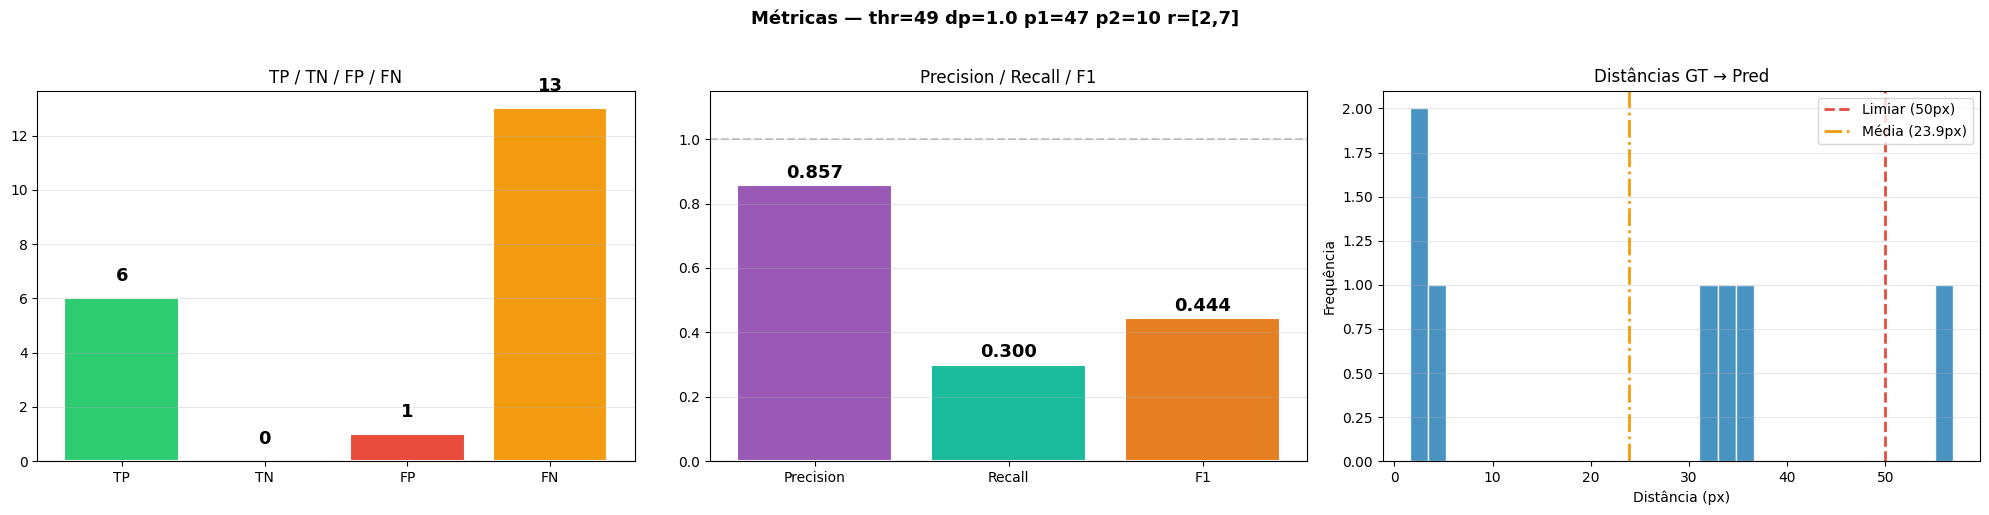

In [19]:
%matplotlib inline

# Lê valores atuais dos sliders
cur_threshold = int(s_threshold.val)
cur_dp = s_dp.val
cur_min_dist = int(s_mindist.val)
cur_param1 = int(s_param1.val)
cur_param2 = int(s_param2.val)
cur_min_radius = int(s_minrad.val)
cur_max_radius = int(s_maxrad.val)

print(f"Avaliando com: threshold={cur_threshold}, dp={cur_dp}, minDist={cur_min_dist}, "
      f"param1={cur_param1}, param2={cur_param2}, r=[{cur_min_radius},{cur_max_radius}]")
print("=" * 80)

tp = [0, 0, 0, 0]
fp = [0, 0, 0, 0]
tn = [0, 0, 0, 0]
fn = [0, 0, 0, 0]
all_distances = []

for r in raw_results:
    x_hm, y_hm, _, _, _ = postprocess_with_params(
        r['feature_map'],
        threshold=cur_threshold, dp=cur_dp, min_dist=cur_min_dist,
        param1=cur_param1, param2=cur_param2,
        min_radius=cur_min_radius, max_radius=cur_max_radius
    )
    vis = r['vis']
    
    if x_hm is not None:
        x_pred_orig, y_pred_orig = hm_to_orig(x_hm, y_hm)
        if vis != 0:
            dst = distance.euclidean((x_pred_orig, y_pred_orig), (r['x_gt'], r['y_gt']))
            all_distances.append(dst)
            if dst < MIN_DIST_THRESHOLD:
                tp[vis] += 1
            else:
                fp[vis] += 1
        else:
            fp[vis] += 1
    else:
        if vis != 0:
            fn[vis] += 1
        else:
            tn[vis] += 1

eps = 1e-15
precision = sum(tp) / (sum(tp) + sum(fp) + eps)
vc1 = tp[1] + fp[1] + tn[1] + fn[1]
vc2 = tp[2] + fp[2] + tn[2] + fn[2]
vc3 = tp[3] + fp[3] + tn[3] + fn[3]
recall = sum(tp) / (vc1 + vc2 + vc3 + eps)
f1 = 2 * precision * recall / (precision + recall + eps)

print(f"\n📊 MÉTRICAS (sobre {len(raw_results)} amostras)")
print(f"  Precision:  {precision:.4f}")
print(f"  Recall:     {recall:.4f}")
print(f"  F1-Score:   {f1:.4f}")
print(f"  TP={sum(tp)}  TN={sum(tn)}  FP={sum(fp)}  FN={sum(fn)}")
if all_distances:
    print(f"  Dist média: {np.mean(all_distances):.2f}px | mediana: {np.median(all_distances):.2f}px")

# Gráficos
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle(f"Métricas — thr={cur_threshold} dp={cur_dp} p1={cur_param1} p2={cur_param2} r=[{cur_min_radius},{cur_max_radius}]",
             fontsize=13, fontweight='bold', y=1.02)

ax = axes[0]
labels_bar = ['TP', 'TN', 'FP', 'FN']
values = [sum(tp), sum(tn), sum(fp), sum(fn)]
colors = ['#2ecc71', '#3498db', '#e74c3c', '#f39c12']
bars = ax.bar(labels_bar, values, color=colors, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
            str(val), ha='center', va='bottom', fontweight='bold', fontsize=13)
ax.set_title('TP / TN / FP / FN', fontsize=12)
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
metrics_names = ['Precision', 'Recall', 'F1']
metrics_vals = [precision, recall, f1]
colors_m = ['#9b59b6', '#1abc9c', '#e67e22']
bars = ax.bar(metrics_names, metrics_vals, color=colors_m, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, metrics_vals):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
            f'{val:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.15)
ax.axhline(y=1.0, color='gray', linestyle='--', alpha=0.4)
ax.set_title('Precision / Recall / F1', fontsize=12)
ax.grid(axis='y', alpha=0.3)

ax = axes[2]
if all_distances:
    ax.hist(all_distances, bins=30, color='#2980b9', edgecolor='white', alpha=0.85)
    ax.axvline(x=MIN_DIST_THRESHOLD, color='#e74c3c', linestyle='--', linewidth=2,
               label=f'Limiar ({MIN_DIST_THRESHOLD}px)')
    ax.axvline(x=np.mean(all_distances), color='#f39c12', linestyle='-.',
               linewidth=2, label=f'Média ({np.mean(all_distances):.1f}px)')
    ax.legend(fontsize=10)
    ax.set_xlabel('Distância (px)')
    ax.set_ylabel('Frequência')
else:
    ax.text(0.5, 0.5, 'Sem detecções', ha='center', va='center',
            fontsize=14, transform=ax.transAxes)
ax.set_title('Distâncias GT → Pred', fontsize=12)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Exportar Melhores Parâmetros

Quando encontrar bons valores, rode a célula abaixo para gerar o snippet pronto.

In [ ]:
print(f"📐 Escala detectada: X={SCALE_X:.1f}, Y={SCALE_Y:.1f} (original: {ORIG_W}x{ORIG_H})")
print("\n📋 Copie este snippet para usar no seu código:\n")
print(f"""def postprocess(feature_map, scale_x={SCALE_X}, scale_y={SCALE_Y}):
    feature_map *= 255
    feature_map = feature_map.reshape(({HEATMAP_H}, {HEATMAP_W}))
    feature_map = feature_map.astype(np.uint8)
    ret, heatmap = cv2.threshold(feature_map, {cur_threshold}, 255, cv2.THRESH_BINARY)
    circles = cv2.HoughCircles(
        heatmap, cv2.HOUGH_GRADIENT,
        dp={cur_dp}, minDist={cur_min_dist},
        param1={cur_param1}, param2={cur_param2},
        minRadius={cur_min_radius}, maxRadius={cur_max_radius}
    )
    x, y = None, None
    if circles is not None:
        if len(circles) == 1:
            x = circles[0][0][0] * scale_x
            y = circles[0][0][1] * scale_y
    return x, y
""")
print(f"# Resultados: P={precision:.4f} R={recall:.4f} F1={f1:.4f}")